<a href="https://colab.research.google.com/github/sebastianvettel1212/Scikit-Learn-Cookbook/blob/main/scikit_learn_Cookbook_Chapter12.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Bab 12 — *Cross-Validation* dan Teknik Evaluasi Model (*Cross-Validation and Model Evaluation Techniques*)

**Buku:** *scikit-learn Cookbook, Third Edition* — John Sukup (Packt Publishing)

Notebook ini berisi:
1. **Reproduksi kode** seluruh *recipe* Bab 12 (dari repositori resmi buku, termasuk solusi latihan),
2. **Ringkasan** tiap subbab, dan
3. **Penjelasan teori** dalam Bahasa Indonesia.

> Sel berlabel **"Tambahan"** adalah contoh pelengkap yang tidak ada di buku. Perbaikan kecil terhadap kode asli buku ditandai dengan komentar `# Catatan:` di dalam sel.

---

## Daftar Isi
0. Persiapan
1. Dasar-Dasar *Cross-Validation* (*Cross-Validation Fundamentals*): *K-Fold* dan *Stratified K-Fold*
2. Teknik *Cross-Validation* Lanjutan: *Leave-One-Out* dan *Nested CV*
3. Menerapkan *Cross-Validation* di scikit-learn
4. Pemilihan Model: `GridSearchCV` dan `RandomizedSearchCV`
5. Menilai Kemampuan Generalisasi: *Learning Curve* dan *Validation Curve*
6. Latihan Praktik
7. Ringkasan Bab

---

## Pengantar
Sebuah model yang baik bukan yang paling akurat pada data latih, melainkan yang **menggeneralisasi** ke data baru. Cara paling sederhana, satu kali pembagian latih/uji (*hold-out*), menghasilkan estimasi yang bergantung pada keberuntungan pembagian. ***Cross-validation* (CV)** mengulang proses latih/uji pada beberapa pembagian lalu merata-ratakan hasilnya sehingga estimasi performa lebih **stabil dan jujur**, dan memungkinkan perbandingan model serta penyetelan hiperparameter yang adil. Bab ini membahas variasi CV, penerapannya di scikit-learn, dan alat diagnosis (*learning curve* dan *validation curve*).

## 0. Persiapan

In [1]:
!pip install numpy pandas scipy scikit-learn matplotlib seaborn

In [2]:
import warnings
warnings.filterwarnings('ignore')
%matplotlib inline

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

print('Versi scikit-learn:', sklearn.__version__)

Versi scikit-learn: 1.6.1


---
## 1. Dasar-Dasar *Cross-Validation*: *K-Fold* dan *Stratified K-Fold*

### Teori
**Masalah hold-out:** satu pembagian 80:20 memberi satu angka yang dapat sangat berbeda bila pembagiannya diacak ulang; selain itu 20% data tidak dipakai melatih.

***K-Fold CV***: data dibagi menjadi $k$ bagian (*fold*) berukuran sama. Untuk $i=1,\dots,k$, model dilatih pada $k-1$ *fold* dan diuji pada *fold* ke-$i$. Estimasi akhir adalah rata-rata skor:
$$\widehat{\text{Skor}}=\frac1k\sum_{i=1}^{k}\text{Skor}_i,\qquad \text{(dilaporkan bersama simpangan baku antar-}fold)$$
Setiap data diuji tepat satu kali dan dipakai melatih $k-1$ kali. Pemilihan $k$ adalah kompromi: $k$ kecil → estimasi lebih bias (data latih lebih sedikit); $k$ besar → bias kecil, variansi dan biaya komputasi lebih besar. $k=5$ atau $10$ umum dipakai.

***Stratified K-Fold***: tiap *fold* mempertahankan **proporsi kelas** data asli. Penting pada data **tak seimbang**, karena pembagian acak biasa bisa membuat sebuah *fold* hampir tak berisi kelas minoritas. Untuk klasifikasi, `cross_val_score(cv=5)` otomatis memakai *stratified*. Parameter `shuffle=True` mengacak data sebelum dibagi (penting bila data berurutan).

Pembagi lain di scikit-learn: `RepeatedStratifiedKFold` (mengulang CV dengan acakan berbeda), `GroupKFold` (data satu kelompok, mis. satu pasien, tidak boleh terpecah antara latih dan uji), dan `TimeSeriesSplit` (data deret waktu: uji selalu **setelah** latih).

### Getting ready
Dataset sintetis 500 sampel, 10 fitur, 2 kelas.

In [3]:
# Load the libraries
import numpy as np
from sklearn.datasets import make_classification
from sklearn.model_selection import KFold, StratifiedKFold
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

# Load the dataset
X, y = make_classification(n_samples=500, n_features=10, n_informative=8,
                           n_redundant=2, n_classes=2, random_state=2024)
print('Proporsi kelas:', np.bincount(y) / len(y))

Proporsi kelas: [0.5 0.5]


### How to do it...
Kita menerapkan *k-fold* dan *stratified k-fold* secara manual dengan regresi logistik.

In [4]:
# Initialize the k-fold cross-validator
kf = KFold(n_splits=5, shuffle=True, random_state=2024)

# Iterate through the folds and evaluate
accuracies = []
for train_index, test_index in kf.split(X):
    X_train, X_test = X[train_index], X[test_index]
    y_train, y_test = y[train_index], y[test_index]
    model = LogisticRegression()
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    accuracies.append(accuracy_score(y_test, y_pred))
print(f"Average accuracy (KFold): {np.mean(accuracies):.3f}")

# Use stratified k-fold for balanced class splits
strat_kf = StratifiedKFold(n_splits=5, shuffle=True, random_state=2024)
strat_accuracies = []
for train_index, test_index in strat_kf.split(X, y):
    X_train, X_test = X[train_index], X[test_index]
    y_train, y_test = y[train_index], y[test_index]
    model = LogisticRegression()
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    strat_accuracies.append(accuracy_score(y_test, y_pred))
print(f"Average accuracy (StratifiedKFold): {np.mean(strat_accuracies):.3f}")
print('Akurasi per fold (KFold)          :', np.round(accuracies, 3))
print('Akurasi per fold (StratifiedKFold):', np.round(strat_accuracies, 3))

Average accuracy (KFold): 0.756
Average accuracy (StratifiedKFold): 0.766
Akurasi per fold (KFold)          : [0.72 0.72 0.88 0.71 0.75]
Akurasi per fold (StratifiedKFold): [0.79 0.76 0.76 0.76 0.76]


**Interpretasi:** rata-rata akurasi *K-Fold* **0,756** dan *Stratified K-Fold* **0,766**, selisih hanya 1 poin. Kelas pada data ini seimbang (50:50), sehingga selisih itu **bukan** akibat stratifikasi, melainkan karena kedua pembagi menghasilkan partisi data yang berbeda. Yang lebih menarik adalah sebaran per *fold*: *K-Fold* berkisar **0,71–0,88** (simpangan baku ≈ 0,07), sedangkan *Stratified* **0,76–0,79** (≈ 0,01). Artinya, satu *fold* saja bisa memberi kesan model berakurasi 0,71 atau 0,88 padahal modelnya sama; inilah alasan perlunya merata-ratakan beberapa *fold* dan melaporkan simpangan baku.

### How it works...
*K-fold* membagi data menjadi *k* bagian sama besar, melatih pada *k−1* bagian, dan menguji pada sisanya; proses diulang *k* kali dan skornya dirata-ratakan. *Stratified k-fold* menjaga proporsi kelas agar tiap *fold* representatif, terutama pada data tak seimbang. Catatan: data pada contoh buku ini hampir seimbang (≈ 50:50), sehingga perbedaan keduanya hampir tak terlihat. Untuk memperlihatkan manfaat stratifikasi, berikut data **sangat tak seimbang** (90:10).

In [5]:
# Tambahan (tidak ada di kode buku): stratifikasi pada data tak seimbang (90:10)
from sklearn.model_selection import RepeatedStratifiedKFold, TimeSeriesSplit, cross_val_score

Xi, yi = make_classification(n_samples=300, n_features=10, n_informative=5, weights=[0.9, 0.1], random_state=2024)
print('Total kelas minoritas:', int(yi.sum()), 'dari', len(yi))

rows = {}
for name, cv in {'KFold (shuffle)': KFold(5, shuffle=True, random_state=2024),
                 'StratifiedKFold': StratifiedKFold(5, shuffle=True, random_state=2024)}.items():
    split = cv.split(Xi, yi)
    rows[name] = [int(yi[test].sum()) for _, test in split]
display(pd.DataFrame(rows, index=[f'fold {i+1}' for i in range(5)]).rename_axis('Jumlah kelas minoritas di data uji'))

# Estimasi F1 (kelas minoritas) dengan pengulangan 5x3
rskf = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=2024)
f1s = cross_val_score(LogisticRegression(max_iter=1000), Xi, yi, cv=rskf, scoring='f1')
print(f'F1 (RepeatedStratifiedKFold 5x3): {f1s.mean():.3f} +/- {f1s.std():.3f} (min {f1s.min():.2f}, maks {f1s.max():.2f})')

# TimeSeriesSplit: data uji selalu SETELAH data latih
for i, (tr, te) in enumerate(TimeSeriesSplit(n_splits=4).split(np.arange(100))):
    print(f'Split {i+1}: latih = indeks 0..{tr[-1]:>2} ({len(tr):>2} data) | uji = indeks {te[0]}..{te[-1]}')

Total kelas minoritas: 32 dari 300


,KFold (shuffle),StratifiedKFold
Jumlah kelas minoritas di data uji,,
fold 1,9,6
fold 2,7,6
fold 3,2,6
fold 4,6,7
fold 5,8,7


F1 (RepeatedStratifiedKFold 5x3): 0.591 +/- 0.185 (min 0.20, maks 0.91)
Split 1: latih = indeks 0..19 (20 data) | uji = indeks 20..39
Split 2: latih = indeks 0..39 (40 data) | uji = indeks 40..59
Split 3: latih = indeks 0..59 (60 data) | uji = indeks 60..79
Split 4: latih = indeks 0..79 (80 data) | uji = indeks 80..99


**Interpretasi:**
- **Stratifikasi pada data 90:10** (32 sampel minoritas dari 300): pada *K-Fold* acak, jumlah sampel minoritas di data uji bervariasi **9, 7, 2, 6, 8**; *fold* ke-3 hanya berisi 2 sampel minoritas sehingga skor F1 di sana nyaris tak bermakna. *Stratified K-Fold* membagi merata: **6, 6, 6, 7, 7**.
- **F1 kelas minoritas** dengan 5×3 pengulangan: rata-rata **0,591**, tetapi rentangnya **0,20–0,91** (std 0,185). Variasi besar ini wajar karena hanya ≈ 6 sampel minoritas per data uji; satu kesalahan menggeser F1 sangat jauh. Pada data tak seimbang, ulangi CV dan laporkan sebarannya.
- **`TimeSeriesSplit`:** jendela latih membesar (20 → 80 data) dan data uji selalu berada **setelah** data latih. Ini mencegah "melihat masa depan", yang akan terjadi bila deret waktu diacak oleh *K-Fold* biasa.

### Key Ideas
- *K-fold CV* memberi estimasi performa yang lebih stabil daripada satu pembagian; laporkan **rata-rata dan simpangan baku**.
- ***Stratified* K-Fold** menjaga proporsi kelas per *fold* dan wajib pada data tak seimbang.
- Pilih pembagi sesuai struktur data: `GroupKFold` untuk data berkelompok, `TimeSeriesSplit` untuk deret waktu.

---
## 2. Teknik *Cross-Validation* Lanjutan: *Leave-One-Out* dan *Nested CV*

### Teori
***Leave-One-Out CV (LOOCV)*** adalah *k-fold* dengan $k=n$: tiap *fold* hanya berisi **satu** sampel. Model dilatih $n$ kali pada $n-1$ sampel. Bias estimasi sangat kecil (hampir semua data dipakai melatih), tetapi biaya komputasi tinggi ($n$ kali pelatihan) dan skor antar-*fold* saling berkorelasi sehingga **variansi estimasi bisa besar**. Cocok untuk dataset kecil.

***Nested CV*** menjawab masalah yang halus: bila hiperparameter disetel dengan CV dan **skor terbaik CV itu juga dilaporkan sebagai performa model**, hasilnya **optimis** karena kita memilih yang terbaik dari banyak kandidat pada data yang sama (kebocoran informasi). Solusinya dua lapis:

- **Loop dalam (*inner*):** `GridSearchCV` memilih hiperparameter hanya dengan data latih milik *fold* luar.
- **Loop luar (*outer*):** menilai performa model hasil pilihan itu pada *fold* luar yang **belum pernah dilihat** proses penyetelan.

Biayanya besar: $k_{luar}\times k_{dalam}\times(\text{jumlah kombinasi})$ pelatihan. Nested CV tidak menghasilkan satu model akhir; ia mengestimasi performa **prosedur** "setel + latih" secara jujur. Model akhir dilatih ulang pada seluruh data dengan hiperparameter terbaik.

### Getting ready
Dataset regresi **Diabetes** (442 sampel, 10 fitur).

In [6]:
# Load the libraries
import numpy as np
from sklearn.datasets import load_diabetes
from sklearn.model_selection import LeaveOneOut, GridSearchCV, cross_val_score
from sklearn.linear_model import Ridge

# Load the dataset
data = load_diabetes()
X = data.data
y = data.target
print('Bentuk data:', X.shape, '| rentang target:', y.min(), '-', y.max(), '| variansi target:', round(y.var(), 1))

Bentuk data: (442, 10) | rentang target: 25.0 - 346.0 | variansi target: 5929.9


### How to do it...
Kita memakai *leave-one-out* dan *nested cross-validation* (skor bawaan regresor = R²).

In [7]:
# Apply Leave-One-Out cross-validation with MSE scoring
loo = LeaveOneOut()
model = Ridge(alpha=1.0)
scores = cross_val_score(model, X, y, cv=loo, scoring="neg_mean_squared_error")
print(f"LOOCV mean MSE: {-np.mean(scores):.3f}")

# Define a grid for hyperparameter tuning
param_grid = {"alpha": [0.01, 0.1, 1, 10, 100]}

# Apply nested cross-validation using GridSearchCV (default scoring is fine for outer CV)
nested_scores = cross_val_score(
    GridSearchCV(Ridge(), param_grid, cv=5), X, y, cv=5
)
print(f"Nested CV mean score: {np.mean(nested_scores):.3f}")
print('Skor R2 per fold luar:', np.round(nested_scores, 3), '| jumlah model pada LOOCV:', len(scores))

LOOCV mean MSE: 3327.655
Nested CV mean score: 0.480
Skor R2 per fold luar: [0.411 0.52  0.492 0.44  0.537] | jumlah model pada LOOCV: 442


**Interpretasi:** LOOCV memberi MSE **3.327,7** (RMSE ≈ 57,7) untuk *Ridge* pada Diabetes; dibandingkan dengan variansi target 5.929,9 (simpangan baku ≈ 77), model menjelaskan sekitar 44% variansi (1 − 3.327,7/5.929,9). *Nested CV* melaporkan **R² rata-rata 0,480** dengan rentang antar-*fold* luar **0,41–0,54**: ketidakpastian ±0,06 terlihat jelas. Kedua angka tidak identik karena metriknya berbeda (MSE vs R² per *fold*), tetapi keduanya sepakat bahwa model linear sederhana menjelaskan kurang dari separuh variansi. LOOCV melatih **442 model** (satu per sampel).

### How it works...
*LOOCV* menguji tiap sampel secara bergantian dengan seluruh sisanya sebagai data latih, sehingga memakai data secara maksimal tetapi mahal pada dataset besar. *Nested CV* memisahkan pemilihan hiperparameter (loop dalam) dari penilaian performa (loop luar) sehingga estimasi tidak optimis.

### Tambahan: seberapa optimis skor terbaik *GridSearchCV*?
Pada data diabetes, selisihnya kecil karena model sederhana dengan 1 hiperparameter. Efeknya jelas pada situasi yang rawan: **data sedikit, banyak fitur noise, dan grid hiperparameter besar**. Eksperimen berikut (data klasifikasi 100 sampel dengan 30% label diacak, SVM dengan 30 kombinasi, diulang 10 kali dengan pembagian *fold* berbeda) membandingkan `best_score_` (tidak *nested*) dengan skor *nested*.

In [8]:
# Tambahan (tidak ada di kode buku)
from sklearn.datasets import make_classification
from sklearn.svm import SVC
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

Xn, yn = make_classification(n_samples=100, n_features=20, n_informative=2, n_redundant=0, flip_y=0.3, random_state=2024)
pipe = make_pipeline(StandardScaler(), SVC())
grid = {'svc__C': [0.01, 0.1, 1, 10, 100], 'svc__gamma': [1e-4, 1e-3, 1e-2, 1e-1, 1, 10]}

non_nested, nested = [], []
for rep in range(10):
    inner = KFold(5, shuffle=True, random_state=rep)
    outer = KFold(5, shuffle=True, random_state=100 + rep)
    non_nested.append(GridSearchCV(pipe, grid, cv=inner).fit(Xn, yn).best_score_)
    nested.append(cross_val_score(GridSearchCV(pipe, grid, cv=inner), Xn, yn, cv=outer).mean())

print(f'Skor terbaik GridSearchCV (tidak nested): {np.mean(non_nested):.3f}  (std antar-ulangan {np.std(non_nested):.3f})')
print(f'Skor nested CV (estimasi jujur)         : {np.mean(nested):.3f}  (std antar-ulangan {np.std(nested):.3f})')
print(f'Selisih (optimisme)                     : {np.mean(non_nested) - np.mean(nested):.3f}')

# Tambahan: LOOCV vs 10-fold pada diabetes (hasil dan jumlah pelatihan)
import time
for name, cv in {'LOOCV': LeaveOneOut(), '10-fold': KFold(10, shuffle=True, random_state=2024)}.items():
    t0 = time.perf_counter()
    s = -cross_val_score(Ridge(alpha=1.0), X, y, cv=cv, scoring='neg_mean_squared_error').mean()
    print(f'{name:8s}: MSE = {s:.1f} | waktu = {time.perf_counter() - t0:.2f} detik')

Skor terbaik GridSearchCV (tidak nested): 0.653  (std antar-ulangan 0.034)
Skor nested CV (estimasi jujur)         : 0.595  (std antar-ulangan 0.034)
Selisih (optimisme)                     : 0.058
LOOCV   : MSE = 3327.7 | waktu = 0.85 detik
10-fold : MSE = 3351.4 | waktu = 0.02 detik


**Interpretasi:**
- **Optimisme skor terbaik `GridSearchCV`:** pada data kecil-berisik (100 sampel, 30% label diacak, 30 kombinasi), skor terbaik tanpa *nested* adalah **0,653**, sedangkan estimasi *nested* **0,595**, selisih (optimisme) **≈ 0,058**, konsisten pada 10 pengulangan (std 0,034). Karena 30% label diacak, akurasi sebenarnya paling banyak sekitar 0,7, sehingga 0,653 tampak "hampir sempurna" padahal sebagian diperoleh karena memilih kombinasi yang kebetulan cocok dengan *fold* tersebut. Pada data besar dengan model sederhana (seperti Ridge pada Diabetes) selisihnya jauh lebih kecil.
- **LOOCV vs 10-fold** pada Diabetes: MSE 3.327,7 vs 3.351,4 (beda ≈ 0,7%), tetapi LOOCV puluhan kali lebih lambat (442 vs 10 pelatihan; sekitar 0,5 detik vs 0,01–0,02 detik, bergantung mesin). Pada ukuran data ini, LOOCV tidak memberi keuntungan praktis dibanding 10-fold.

### Key Ideas
- **LOOCV** memakai hampir semua data untuk melatih (bias kecil) tetapi mahal dan berskor antar-*fold* berkorelasi.
- Skor terbaik `GridSearchCV` bersifat **optimis**; gunakan ***nested CV*** untuk estimasi jujur performa prosedur penyetelan.
- Nested CV mahal: jumlah pelatihan = $k_{luar}\times k_{dalam}\times$ jumlah kombinasi.

---
## 3. Menerapkan *Cross-Validation* di scikit-learn

### Teori
scikit-learn menyediakan tiga fungsi tingkat tinggi sehingga loop manual tidak perlu ditulis:

| Fungsi | Kegunaan | Keluaran |
|---|---|---|
| `cross_val_score` | satu metrik cepat | array skor per *fold* |
| `cross_validate` | **banyak metrik** sekaligus, waktu, dan skor latih | kamus (`test_<metrik>`, `fit_time`, ...) |
| `GridSearchCV` | penyetelan hiperparameter dengan CV | `best_params_`, `best_score_`, `best_estimator_` |

Tambahan: `cross_val_predict` mengembalikan prediksi *out-of-fold* untuk **setiap** sampel (berguna untuk *confusion matrix*), tetapi **jangan** dipakai untuk menghitung skor rata-rata sebagai pengganti `cross_val_score`.

**Pitfall paling penting: kebocoran data (*data leakage*).** Setiap langkah yang "belajar dari data" (standardisasi, seleksi fitur, imputasi) harus dilakukan **di dalam** tiap *fold* pelatihan. Caranya: bungkus semuanya dalam `Pipeline` lalu kirim ke fungsi CV (lihat Bab 1–2).

### Getting ready
Dataset 500 sampel, 10 fitur, **tak seimbang** (70:30).

In [9]:
# Load the libraries
import numpy as np
from sklearn.datasets import make_classification
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score, cross_validate, GridSearchCV

# Load and prepare the dataset
X, y = make_classification(n_samples=500, n_features=10, weights=[0.7, 0.3], random_state=2024)
print('Proporsi kelas:', np.bincount(y) / len(y))

Proporsi kelas: [0.7 0.3]


### How to do it...
Tiga cara melakukan CV dengan API tingkat tinggi.

In [10]:
# Use cross_val_score() to compute average accuracy
model = LogisticRegression()
scores = cross_val_score(model, X, y, cv=5, scoring='accuracy')
print(f"Mean accuracy: {np.mean(scores):.3f}")

# Use cross_validate() to compute multiple metrics
results = cross_validate(model, X, y, cv=5,
                         scoring=['accuracy', 'precision', 'recall', 'f1'])
print(f"Mean precision: {np.mean(results['test_precision']):.3f}")
print(f"Mean recall: {np.mean(results['test_recall']):.3f}")
print(f"Mean F1: {np.mean(results['test_f1']):.3f}")

# Use GridSearchCV() for hyperparameter tuning with cross-validation
param_grid = {"C": [0.01, 0.1, 1, 10]}
grid = GridSearchCV(LogisticRegression(), param_grid, cv=5, scoring='accuracy')
grid.fit(X, y)
print(f"Best hyperparameter (C): {grid.best_params_['C']}")
print(f"Best accuracy: {grid.best_score_:.3f}")

Mean accuracy: 0.910
Mean precision: 0.875
Mean recall: 0.820
Mean F1: 0.845
Best hyperparameter (C): 0.1
Best accuracy: 0.918


**Interpretasi:** pada data tak seimbang 70:30, akurasi rata-rata **0,910** (jauh di atas *baseline* 0,70 untuk menebak kelas mayoritas), tetapi *recall* hanya **0,820** dan F1 **0,845**: akurasi tinggi menutupi bahwa sekitar 18% kelas minoritas terlewat. `GridSearchCV` memilih `C=0.1` dengan skor CV 0,918, sedikit di atas `C=1` bawaan (0,910). Ingat skor terbaik tersebut bersifat sedikit optimis (lihat *nested CV*).

### How it works...
`cross_val_score()` cepat untuk satu metrik; `cross_validate()` mengembalikan banyak metrik (dan waktu); `GridSearchCV()` menggabungkan penyetelan dan CV serta menyimpan model terbaik.

### Tambahan: rincian per metrik, prediksi *out-of-fold*, dan jebakan kebocoran data

In [11]:
# Tambahan (tidak ada di kode buku)
from sklearn.metrics import confusion_matrix
from sklearn.model_selection import cross_val_predict, StratifiedKFold
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.pipeline import make_pipeline

cv5 = StratifiedKFold(5, shuffle=True, random_state=2024)
res = cross_validate(LogisticRegression(), X, y, cv=cv5, return_train_score=True,
                     scoring=['accuracy', 'balanced_accuracy', 'precision', 'recall', 'f1', 'roc_auc'])
summary = pd.DataFrame({m: {'Latih': res[f'train_{m}'].mean(), 'Uji (CV)': res[f'test_{m}'].mean(), 'Std uji': res[f'test_{m}'].std()}
                        for m in ['accuracy', 'balanced_accuracy', 'precision', 'recall', 'f1', 'roc_auc']}).T
display(summary.round(3))
print(f"Rata-rata waktu latih per fold: {res['fit_time'].mean():.4f} detik")

# Prediksi out-of-fold untuk membuat confusion matrix
pred = cross_val_predict(LogisticRegression(), X, y, cv=cv5)
print('Confusion matrix out-of-fold (baris=aktual, kolom=prediksi):')
print(confusion_matrix(y, pred))

# Jebakan kebocoran data: seleksi fitur pada data yang SEMUANYA noise (label acak)
rng = np.random.RandomState(2024)
Xn = rng.randn(100, 1000); yn = rng.randint(0, 2, 100)

X_sel = SelectKBest(f_classif, k=10).fit_transform(Xn, yn)      # SALAH: seleksi memakai seluruh data (termasuk label uji)
leaky = cross_val_score(LogisticRegression(), X_sel, yn, cv=5).mean()
pipe = make_pipeline(SelectKBest(f_classif, k=10), LogisticRegression())   # BENAR: seleksi di dalam tiap fold
clean = cross_val_score(pipe, Xn, yn, cv=5).mean()
print(f'Data murni noise (akurasi sebenarnya = 0,5): seleksi di luar CV -> {leaky:.3f} | di dalam Pipeline -> {clean:.3f}')

,Latih,Uji (CV),Std uji
accuracy,0.922,0.914,0.019
balanced_accuracy,0.892,0.878,0.031
precision,0.909,0.916,0.026
recall,0.820,0.787,0.065
f1,0.862,0.845,0.037
roc_auc,0.971,0.962,0.022


Rata-rata waktu latih per fold: 0.0031 detik
Confusion matrix out-of-fold (baris=aktual, kolom=prediksi):
[[339  11]
 [ 32 118]]
Data murni noise (akurasi sebenarnya = 0,5): seleksi di luar CV -> 0.750 | di dalam Pipeline -> 0.540


**Interpretasi:**
- **Rincian per metrik (CV, uji):** akurasi 0,914, *balanced accuracy* 0,878, precision 0,916, **recall 0,787** (std 0,065, paling tidak stabil), F1 0,845, ROC-AUC **0,962**. Skor latih hanya sedikit di atas skor uji (mis. akurasi 0,922 vs 0,914), tanda *overfitting* kecil.
- ***Confusion matrix out-of-fold***: 339 benar dan 11 salah untuk kelas mayoritas; **118 benar dan 32 terlewat** untuk kelas minoritas (recall 118/150 = 0,787).
- **Kebocoran data:** pada data **murni noise** (label acak, akurasi sebenarnya 0,5), seleksi fitur yang dilakukan **di luar** CV memberi akurasi **0,750** (seolah model hebat!), sedangkan seleksi **di dalam `Pipeline`** memberi **0,540** (mendekati kenyataan). Seleksi di luar CV "mengintip" label data uji saat memilih fitur. Ini contoh paling jelas mengapa praproses yang belajar dari data harus berada di dalam *Pipeline*.

### Key Ideas
- `cross_val_score` (satu metrik), `cross_validate` (banyak metrik + waktu + skor latih), `GridSearchCV` (penyetelan).
- Pada data tak seimbang, laporkan lebih dari akurasi (precision, recall, F1, ROC-AUC, *balanced accuracy*).
- Bungkus praproses dalam `Pipeline` agar langkah yang belajar dari data tidak bocor ke *fold* uji.

---
## 4. Pemilihan Model: `GridSearchCV` dan `RandomizedSearchCV`

### Teori
- **`GridSearchCV`** mencoba **semua kombinasi** pada grid. Jumlah pelatihan = (jumlah kombinasi) × (jumlah *fold*). Menyeluruh, tetapi biaya tumbuh eksponensial terhadap jumlah hiperparameter.
- **`RandomizedSearchCV`** mengambil `n_iter` kombinasi **acak** dari distribusi (mis. `loguniform` untuk `C`), sehingga biayanya tetap **`n_iter` × jumlah *fold*** berapa pun besar ruang pencarian. Terbukti efektif bila hanya sebagian hiperparameter yang benar-benar berpengaruh (Bergstra & Bengio, 2012), dan dapat menjelajahi nilai kontinu di antara titik-titik grid.
- Keduanya menyimpan `best_params_`, `best_score_`, `best_estimator_`; **performa akhir tetap dilaporkan pada data uji terpisah**.
- Untuk membandingkan **algoritma berbeda**, jalankan CV dengan **pembagian *fold* yang sama** agar perbandingannya adil.

### Getting ready
Dataset 500 sampel (70:30) dengan pembagian latih/uji 70:30.

In [12]:
# Load the libraries
import numpy as np
from sklearn.datasets import make_classification
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV, train_test_split
from sklearn.metrics import accuracy_score

# Load and split the dataset
X, y = make_classification(n_samples=500, n_features=10, weights=[0.7, 0.3], random_state=2024)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=2024)

### How to do it...
Membandingkan `GridSearchCV` dan `RandomizedSearchCV` untuk mencari nilai regularisasi `C` terbaik.

In [13]:
# Use GridSearchCV to evaluate all combinations in the parameter grid
param_grid = {"C": [0.001, 0.01, 0.1, 1, 10, 100]}
grid = GridSearchCV(LogisticRegression(), param_grid, cv=5, scoring='accuracy')
grid.fit(X_train, y_train)
print(f"GridSearchCV best C: {grid.best_params_['C']}")

# Use RandomizedSearchCV to evaluate a random sample of parameters
from scipy.stats import loguniform
param_dist = {"C": loguniform(1e-3, 1e2)}
random_search = RandomizedSearchCV(LogisticRegression(), param_distributions=param_dist,
                                    n_iter=10, cv=5, scoring='accuracy', random_state=2024)
random_search.fit(X_train, y_train)
print(f"RandomizedSearchCV best C: {random_search.best_params_['C']:.4f}")

# Evaluate final model performance
final_model = random_search.best_estimator_
y_pred = final_model.predict(X_test)
print(f"Final accuracy on test set: {accuracy_score(y_test, y_pred):.3f}")
print(f'Skor CV terbaik: grid = {grid.best_score_:.3f} | random = {random_search.best_score_:.3f}')
print(f'Jumlah pelatihan: grid = {len(param_grid["C"]) * 5} | random = {10 * 5}')

GridSearchCV best C: 0.1
RandomizedSearchCV best C: 0.1744
Final accuracy on test set: 0.940
Skor CV terbaik: grid = 0.894 | random = 0.897
Jumlah pelatihan: grid = 30 | random = 50


**Interpretasi:** *grid search* memilih `C=0.1`, sedangkan *randomized search* menemukan `C≈0,1744`, nilai kontinu di antara titik grid 0,1 dan 1. Skor CV hampir sama (0,894 vs 0,897) dan akurasi uji akhir **0,940** (150 data uji). Perhatikan jumlah pelatihan: **grid 30** (6 nilai × 5 *fold*) justru **lebih sedikit** daripada **random 50** (10 iterasi × 5 *fold*). *Randomized search* hanya menghemat biaya bila grid jauh lebih besar daripada `n_iter`; pada grid satu hiperparameter dengan 6 nilai seperti ini, tidak ada penghematan.

### How it works...
`GridSearchCV()` melakukan pencarian menyeluruh (andal tetapi mahal), sedangkan `RandomizedSearchCV()` mengambil sampel acak dari ruang parameter (lebih efisien pada ruang besar).

### Tambahan: membandingkan beberapa algoritma dengan *fold* yang sama

,F1 rata-rata,Std
Random forest,0.862,0.047
Naive Bayes,0.854,0.056
SVM (RBF),0.846,0.048
Regresi logistik,0.840,0.049
KNN (k=5),0.803,0.054


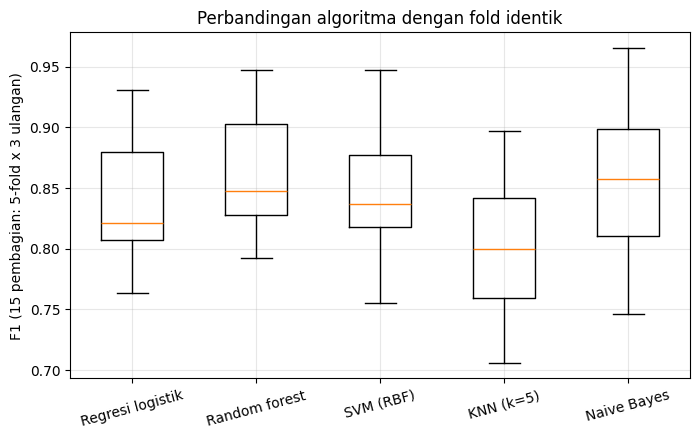

In [14]:
# Tambahan (tidak ada di kode buku)
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import RepeatedStratifiedKFold

cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=2024)   # fold IDENTIK untuk semua model
candidates = {
    'Regresi logistik': make_pipeline(StandardScaler(), LogisticRegression()),
    'Random forest': RandomForestClassifier(n_estimators=200, random_state=2024),
    'SVM (RBF)': make_pipeline(StandardScaler(), SVC()),
    'KNN (k=5)': make_pipeline(StandardScaler(), KNeighborsClassifier()),
    'Naive Bayes': GaussianNB(),
}
all_scores = {name: cross_val_score(m, X, y, cv=cv, scoring='f1') for name, m in candidates.items()}
table = pd.DataFrame({'F1 rata-rata': {k: v.mean() for k, v in all_scores.items()},
                      'Std': {k: v.std() for k, v in all_scores.items()}}).sort_values('F1 rata-rata', ascending=False)
display(table.round(3))

plt.figure(figsize=(8, 4.5))
plt.boxplot(list(all_scores.values()), labels=list(all_scores.keys()))
plt.ylabel('F1 (15 pembagian: 5-fold x 3 ulangan)'); plt.title('Perbandingan algoritma dengan fold identik'); plt.xticks(rotation=15); plt.grid(alpha=0.3); plt.show()

**Interpretasi:** (F1, 15 pembagian identik) *Random forest* 0,862, *Naive Bayes* 0,854, SVM-RBF 0,846, regresi logistik 0,840, dan KNN 0,803. Simpangan baku masing-masing sekitar 0,05, sehingga **empat model teratas tidak dapat dibedakan secara meyakinkan** (selisih 2 poin < 1 simpangan baku, dan kotak pada *boxplot* tumpang-tindih); hanya KNN yang tampak tertinggal. Karena *fold* sama dipakai untuk semua model, perbandingannya adil; peringkat tipis sebaiknya tidak dijadikan dasar kesimpulan kuat.

### Key Ideas
- *Grid search* = menyeluruh dan mahal; *randomized search* = biaya tetap `n_iter` × *fold*, unggul bila ruang pencarian besar.
- Jika grid hanya berisi sedikit kombinasi, *grid search* bisa lebih murah daripada *randomized search*.
- Bandingkan algoritma dengan **fold yang sama** dan laporkan sebaran skor, bukan hanya rata-rata.

---
## 5. Menilai Kemampuan Generalisasi: *Learning Curve* dan *Validation Curve*

### Teori
Dua alat diagnosis visual:

- ***Learning curve*** memplot skor latih dan skor validasi terhadap **ukuran data latih**. Cara membacanya:

| Pola | Diagnosis | Obat |
|---|---|---|
| kedua kurva **rendah** dan berdekatan | ***high bias* / *underfitting*** | model lebih kompleks, fitur lebih baik |
| skor latih **tinggi**, skor validasi **jauh lebih rendah** (celah besar) | ***high variance* / *overfitting*** | **lebih banyak data**, regularisasi, model lebih sederhana |
| kedua kurva **menyatu** di nilai tinggi | generalisasi baik | – |
| kurva validasi **masih naik** di ujung kanan | tambahan data masih membantu | kumpulkan lebih banyak data |

- ***Validation curve*** memplot skor latih dan validasi terhadap **satu hiperparameter** (mis. `C`), sehingga terlihat wilayah *underfitting* (kedua skor rendah), titik optimal (skor validasi puncak), dan wilayah *overfitting* (skor latih naik, skor validasi turun).

Skor biasanya dirata-ratakan dari *fold* CV; pita simpangan baku menunjukkan ketidakpastian.

### Getting ready
Dataset 1.000 sampel, 20 fitur, 70:30.

In [15]:
# Load the libraries
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_classification
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import learning_curve, validation_curve

# Load the dataset
X, y = make_classification(n_samples=1000, n_features=20, weights=[0.7, 0.3], random_state=2024)

### How to do it...
Pertama *learning curve*, lalu *validation curve* untuk `C`.

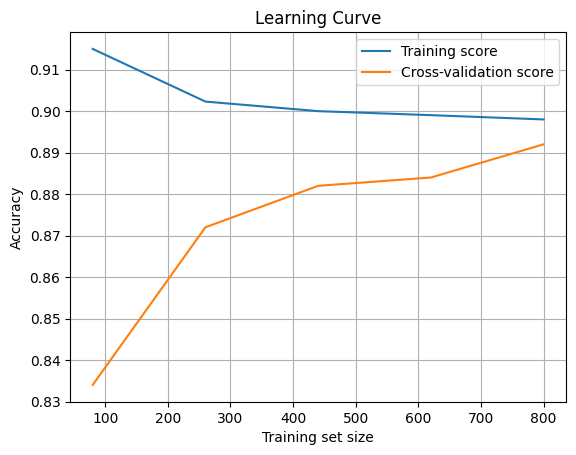

Ukuran data latih: [ 80 260 440 620 800] 
Skor latih  : [0.915 0.902 0.9   0.899 0.898] 
Skor validasi: [0.834 0.872 0.882 0.884 0.892]


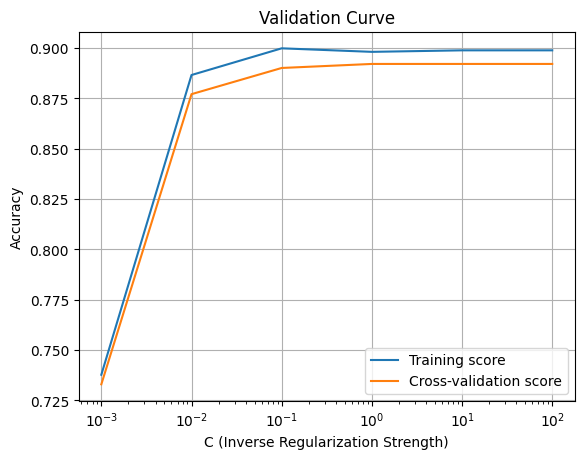

C       : [1.e-03 1.e-02 1.e-01 1.e+00 1.e+01 1.e+02] 
Skor latih  : [0.738 0.887 0.9   0.898 0.899 0.899] 
Skor validasi: [0.733 0.877 0.89  0.892 0.892 0.892]


In [16]:
# Plot a learning curve
train_sizes, train_scores, test_scores = learning_curve(
    LogisticRegression(), X, y, cv=5, scoring='accuracy', train_sizes=np.linspace(0.1, 1.0, 5), random_state=2024)

train_mean = np.mean(train_scores, axis=1)
test_mean = np.mean(test_scores, axis=1)

plt.plot(train_sizes, train_mean, label='Training score')
plt.plot(train_sizes, test_mean, label='Cross-validation score')
plt.xlabel('Training set size')
plt.ylabel('Accuracy')
plt.title('Learning Curve')
plt.legend()
plt.grid(True)
plt.show()
print('Ukuran data latih:', train_sizes, '\nSkor latih  :', train_mean.round(3), '\nSkor validasi:', test_mean.round(3))

# Plot a validation curve
param_range = np.logspace(-3, 2, 6)
train_scores, test_scores = validation_curve(
    LogisticRegression(), X, y, param_name="C", param_range=param_range,
    cv=5, scoring='accuracy')

train_mean = np.mean(train_scores, axis=1)
test_mean = np.mean(test_scores, axis=1)

plt.semilogx(param_range, train_mean, label='Training score')
plt.semilogx(param_range, test_mean, label='Cross-validation score')
plt.xlabel('C (Inverse Regularization Strength)')
plt.ylabel('Accuracy')
plt.title('Validation Curve')
plt.legend()
plt.grid(True)
plt.show()
print('C       :', param_range, '\nSkor latih  :', train_mean.round(3), '\nSkor validasi:', test_mean.round(3))

**Interpretasi:**
- ***Learning curve*:** celah antara skor latih dan validasi menyempit dari 0,081 (n=80: 0,915 vs 0,834) menjadi **0,006** (n=800: 0,898 vs 0,892). Skor validasi naik 0,834 → 0,892 lalu hampir mendatar, jadi menambah data **tidak akan banyak membantu** lagi; batas performa ditentukan oleh model (≈ 0,89).
- ***Validation curve*:** `C=0.001` menghasilkan *underfitting* (latih 0,738, validasi 0,733); mulai `C≥0.01` skor naik ke ≈ 0,89 dan mendatar. Skor validasi tertinggi 0,892 pada `C≥1`. Tidak terlihat wilayah *overfitting* pada rentang ini, karena 800 sampel dengan 20 fitur cukup untuk model linear.

### How it works...
*Learning curve* memperlihatkan bagaimana akurasi latih dan validasi berubah seiring bertambahnya data: celah besar menandakan *overfitting*, kedua kurva yang menyatu menandakan generalisasi baik. *Validation curve* membantu menentukan apakah model *underfitting* atau *overfitting* pada berbagai tingkat kompleksitas: `C` kecil berarti regularisasi kuat (berpotensi *underfitting*), `C` besar berarti regularisasi lemah (berpotensi *overfitting*).

### Tambahan: kontras model sederhana vs model fleksibel
Pada data yang sama, regresi logistik (bias lebih tinggi) dibandingkan *random forest* (variansi lebih tinggi), lengkap dengan pita simpangan baku.

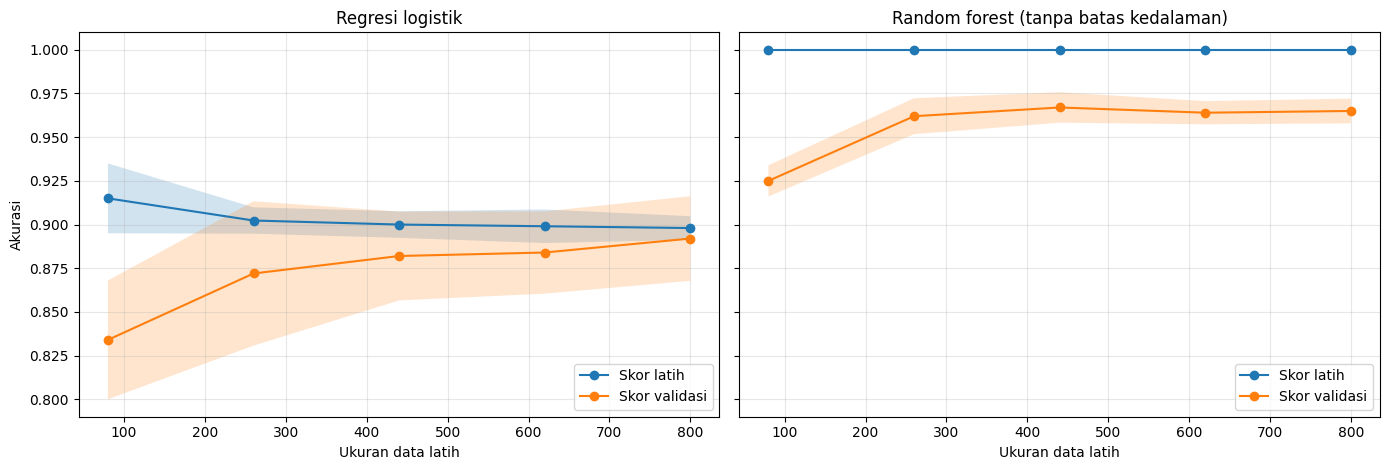

,Skor latih (data penuh),Skor validasi (data penuh),Celah
Regresi logistik,0.898,0.892,0.006
Random forest (tanpa batas kedalaman),1.000,0.965,0.035


In [17]:
# Tambahan (tidak ada di kode buku)
from sklearn.ensemble import RandomForestClassifier

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8), sharey=True)
gaps = {}
for ax, (name, est) in zip(axes, {'Regresi logistik': LogisticRegression(),
                                   'Random forest (tanpa batas kedalaman)': RandomForestClassifier(n_estimators=100, random_state=2024)}.items()):
    ts, tr, te = learning_curve(est, X, y, cv=5, scoring='accuracy', train_sizes=np.linspace(0.1, 1.0, 5), random_state=2024)
    for scores, label in [(tr, 'Skor latih'), (te, 'Skor validasi')]:
        m, s = scores.mean(axis=1), scores.std(axis=1)
        ax.plot(ts, m, 'o-', label=label); ax.fill_between(ts, m - s, m + s, alpha=0.2)
    ax.set_title(name); ax.set_xlabel('Ukuran data latih'); ax.grid(alpha=0.3); ax.legend(loc='lower right')
    gaps[name] = (tr.mean(axis=1)[-1], te.mean(axis=1)[-1])
axes[0].set_ylabel('Akurasi'); plt.tight_layout(); plt.show()
pd.DataFrame(gaps, index=['Skor latih (data penuh)', 'Skor validasi (data penuh)']).T.assign(Celah=lambda d: d.iloc[:, 0] - d.iloc[:, 1]).round(3)

**Interpretasi:** celah kecil **tidak otomatis berarti model bagus**. Regresi logistik: skor latih 0,898 vs validasi 0,892 (celah 0,006), tetapi kedua kurva menyatu pada level yang **rendah**, tanda ***high bias***: model linear tidak cukup fleksibel untuk data ini. *Random forest* memiliki celah lebih besar (latih **1,000** vs validasi **0,965**, celah 0,035; ciri variansi lebih tinggi) tetapi skor validasinya **jauh lebih tinggi** (0,965 vs 0,892). Jadi bacalah *learning curve* dengan memperhatikan **level** skor dan **celah** sekaligus: untuk regresi logistik obatnya bukan lebih banyak data, melainkan model yang lebih ekspresif.

### Key Ideas
- ***Learning curve***: celah besar = *overfitting* (butuh data/regularisasi); kedua kurva rendah = *underfitting* (butuh model lebih kompleks).
- ***Validation curve***: temukan titik optimal hiperparameter antara *underfitting* dan *overfitting*.
- Kedua alat ini mengarahkan keputusan: kumpulkan data lagi, ubah kompleksitas model, atau ubah regularisasi.

---
## 6. Latihan Praktik (*Practical Exercises in Cross-Validation and Evaluation*)

Berikut solusi ketiga latihan dari berkas *Exercise Solutions* repositori resmi buku, dilengkapi interpretasi.

### Latihan 1: *Cross-Validation* dengan Banyak Metrik
Menggunakan `cross_validate` untuk mengumpulkan akurasi, precision, recall, dan F1.

In [18]:
# Load libraries
from sklearn.datasets import make_classification
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_validate

# Load the dataset
X, y = make_classification(n_samples=500, n_features=10, random_state=2024)

# Cross-validate and collect metrics
model = LogisticRegression()
results = cross_validate(model, X, y, cv=5, scoring=["accuracy", "precision", "recall", "f1"])

for metric in ["test_accuracy", "test_precision", "test_recall", "test_f1"]:
    print(f"{metric}: {results[metric].mean():.3f}")
print('Akurasi per fold:', results['test_accuracy'].round(3))

test_accuracy: 0.896
test_precision: 0.896
test_recall: 0.895
test_f1: 0.895
Akurasi per fold: [0.82 0.94 0.89 0.91 0.92]


**Interpretasi:** pada data seimbang, keempat metrik hampir sama: akurasi 0,896, precision 0,896, recall 0,895, F1 0,895. Per *fold* akurasi berkisar **0,82–0,94**; selisih 12 poin antar-*fold* menegaskan mengapa rata-rata dan simpangan baku, bukan satu *fold*, yang dilaporkan.

### Latihan 2: Penyetelan Hiperparameter dengan *Grid Search*
Menyetel `C` dan `kernel` pada SVM.

In [19]:
# Load libraries
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.svm import SVC
from sklearn.metrics import classification_report

# Load and split the dataset
X, y = make_classification(n_samples=500, n_features=10, random_state=2024)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=2024)

# Perform grid search
param_grid = {"C": [0.1, 1, 10], "kernel": ["linear", "rbf"]}
grid = GridSearchCV(SVC(), param_grid, cv=5)
grid.fit(X_train, y_train)
print(f"Best parameters: {grid.best_params_} | skor CV terbaik = {grid.best_score_:.3f}")

# Evaluate on the test set
y_pred = grid.predict(X_test)
print(classification_report(y_test, y_pred))

Best parameters: {'C': 0.1, 'kernel': 'rbf'} | skor CV terbaik = 0.897
              precision    recall  f1-score   support

           0       0.94      0.86      0.89        84
           1       0.84      0.92      0.88        66

    accuracy                           0.89       150
   macro avg       0.89      0.89      0.89       150
weighted avg       0.89      0.89      0.89       150



**Interpretasi:** *grid search* memilih **`C=0.1` dengan kernel RBF** (skor CV 0,897); pada 150 data uji akurasi **0,89**, dengan kelas 0 precision 0,94/recall 0,86 dan kelas 1 precision 0,84/recall 0,92. Skor CV (0,897) dan akurasi uji (0,89) yang berdekatan menandakan estimasi yang konsisten dan tidak *overfit* pada data uji.

### Latihan 3: *Learning Curve* dan *Validation Curve*
Menilai generalisasi regresi logistik pada data Latihan 2.

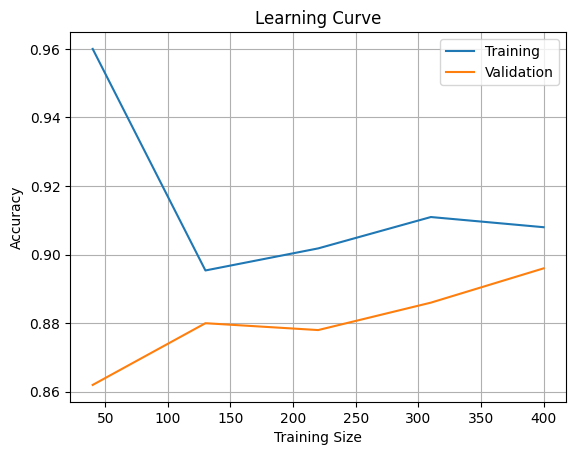

Skor latih  : [0.96  0.895 0.902 0.911 0.908] 
Skor validasi: [0.862 0.88  0.878 0.886 0.896]


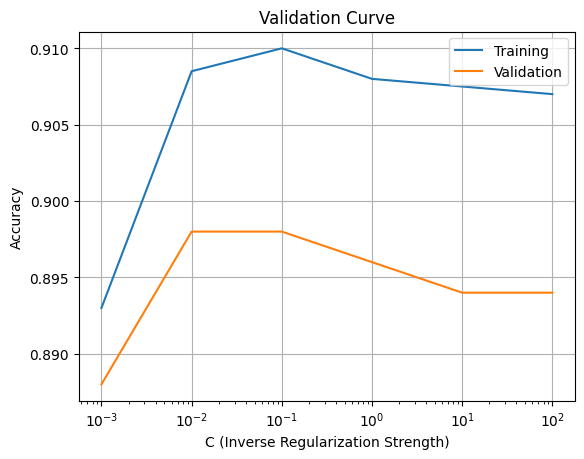

C           : [1.e-03 1.e-02 1.e-01 1.e+00 1.e+01 1.e+02] 
Skor latih  : [0.893 0.908 0.91  0.908 0.908 0.907] 
Skor validasi: [0.888 0.898 0.898 0.896 0.894 0.894]


In [20]:
# Load libraries
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import learning_curve, validation_curve

# Plot the learning curve
train_sizes, train_scores, test_scores = learning_curve(
    LogisticRegression(), X, y, cv=5, scoring='accuracy', train_sizes=np.linspace(0.1, 1.0, 5), random_state=2024)

plt.plot(train_sizes, train_scores.mean(axis=1), label="Training")
plt.plot(train_sizes, test_scores.mean(axis=1), label="Validation")
plt.title("Learning Curve")
plt.xlabel("Training Size")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.show()
print('Skor latih  :', train_scores.mean(axis=1).round(3), '\nSkor validasi:', test_scores.mean(axis=1).round(3))

# Plot the validation curve
param_range = np.logspace(-3, 2, 6)
train_scores, test_scores = validation_curve(
    LogisticRegression(), X, y, param_name="C", param_range=param_range,
    cv=5, scoring='accuracy')

plt.semilogx(param_range, train_scores.mean(axis=1), label="Training")
plt.semilogx(param_range, test_scores.mean(axis=1), label="Validation")
plt.title("Validation Curve")
plt.xlabel("C (Inverse Regularization Strength)")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.show()
print('C           :', param_range, '\nSkor latih  :', train_scores.mean(axis=1).round(3), '\nSkor validasi:', test_scores.mean(axis=1).round(3))

**Interpretasi:**
- ***Learning curve*:** skor latih turun dari 0,960 (n=80) ke 0,908, skor validasi naik dari 0,862 ke 0,896; celah menyempit dari ≈ 0,10 menjadi ≈ 0,01. Kurva validasi masih sedikit naik di ujung, sehingga tambahan data mungkin masih membantu sedikit (≈ 1 poin).
- ***Validation curve*:** skor validasi memuncak pada `C=0.01–0.1` (0,898) lalu turun tipis menjadi 0,894 untuk `C` besar, sementara skor latih naik. Ini jejak awal *overfitting* ringan, tetapi selisihnya hanya 0,4 poin, jadi model ini stabil terhadap pilihan `C` di rentang tersebut.

---
## 7. Ringkasan Bab

Bab ini membahas cara **mengevaluasi model secara jujur**: variasi *cross-validation* (K-Fold, Stratified, LOOCV, Nested), penerapannya lewat API scikit-learn, pemilihan model dengan pencarian hiperparameter, dan diagnosis generalisasi dengan kurva pembelajaran/validasi.

### Rangkuman Konsep dan Fungsi
| Subbab | Konsep utama | Kelas/Fungsi scikit-learn |
|---|---|---|
| Dasar CV | K-Fold, Stratified K-Fold, estimasi stabil | `KFold`, `StratifiedKFold`, `RepeatedStratifiedKFold`, `TimeSeriesSplit` |
| CV lanjutan | LOOCV, *nested CV* (estimasi jujur setelah penyetelan) | `LeaveOneOut`, `GridSearchCV` di dalam `cross_val_score` |
| Penerapan | skor tunggal, banyak metrik, penyetelan; kebocoran data | `cross_val_score`, `cross_validate`, `cross_val_predict`, `Pipeline` |
| Pemilihan model | pencarian menyeluruh vs acak; bandingkan algoritma dengan *fold* sama | `GridSearchCV`, `RandomizedSearchCV`, `scipy.stats.loguniform` |
| Generalisasi | *learning curve* (data), *validation curve* (hiperparameter) | `learning_curve`, `validation_curve` |
| Latihan | multi-metrik, *grid search* SVM, kurva diagnosis | `cross_validate`, `GridSearchCV`, `SVC` |

**Pesan utama:** satu angka dari satu pembagian data tidak cukup. Gunakan **CV (stratified bila kelas tak seimbang)**, laporkan **rata-rata dan simpangan baku**, bungkus praproses dalam `Pipeline` agar tidak ada kebocoran data, pakai ***nested CV*** bila ingin melaporkan performa setelah penyetelan, dan gunakan kurva pembelajaran/validasi untuk memutuskan apakah masalahnya data, kompleksitas, atau regularisasi.